# Actividad: Aceites adulterados

**Nombre:** Mateo Flores  
**Materia:** Aplicación de métodos multivariados en ciencia de datos  
**Fecha:** 11 de octubre de 2026

El objetivo de este trabajo es estudiar las diferencias entre las muestras de aceite y resumir sus mediciones con componentes principales. Primero limpio los datos fisicoquímicos y después analizo las mediciones espectroscópicas.

Los datos provienen de `olive_oil.csv` y `spectra.csv`. El procedimiento sigue los ejemplos del material **Análisis de componentes principales**, del Dr. Javier E. Garrido Guillén.

Para repetir el análisis, se ejecutan las celdas en orden. En la carpeta de la actividad, los CSV están en `../data/`. También se permite una carpeta `data/` junto al notebook. Se necesitan pandas, numpy, matplotlib, seaborn y scikit-learn. El PCA y la SVD utilizados son deterministas; además, se fija una semilla.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

np.random.seed(123)
sns.set_theme(style = "whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 60)

ruta = Path("../data")
if not (ruta / "olive_oil.csv").exists():
    ruta = Path("data")

data = pd.read_csv(ruta / "olive_oil.csv", dtype = str, keep_default_na = False)
display(data.head())
print("Filas y columnas:", data.shape)

,Muestra,acidez libre,Peroxidos mEq O2/kg,K232,K270,Fenoles mg/kg,Ácido oléico,Acido Linoleico,acidopalmitico,cera mg/kg,CLOROFILA
0,M001,,,,,,,,,,
1,M002,1.298,16.369,2.007,0.177,397.062,71.976,9.700,11.978,201.227,11.451
2,M003,0.734,15.257,2.308,0.280,142.530,72.977,8.038,11.889,144.826,2.221
3,M004,0.838,9.873,1.751,0.127,423.678,72.566,9.057,11.825,158.535,10.595
4,M005,0.90%,13.304,2.220,0.198,315.145,73.62%,7.70%,11.59%,169.003,7.604


Filas y columnas: (120, 11)


## 1. Limpieza de los datos

Conservo `muestra` como identificador, pero no la incluyo en el PCA porque no es una medición. Los nombres de las columnas se convierten a minúsculas, se eliminan acentos y unidades, y los espacios se reemplazan por guiones bajos. También unifico los nombres de ácido palmítico y ceras.

In [2]:
def limpiar_nombre(nombre):
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = nombre.encode("ascii", "ignore").decode().lower().strip()
    nombre = re.sub(r"\s*(meq\s*o2/kg|mg/kg|%)", "", nombre)
    nombre = re.sub(r"\s+", "_", nombre)
    return nombre

data.columns = [limpiar_nombre(nombre) for nombre in data.columns]
data = data.rename(columns = {"acidopalmitico": "acido_palmitico", "cera": "ceras"})
original = data.copy()
display(pd.DataFrame({"Columna limpia": data.columns}))

,Columna limpia
0,muestra
1,acidez_libre
2,peroxidos
3,k232
4,k270
5,fenoles
6,acido_oleico
7,acido_linoleico
8,acido_palmitico
9,ceras


En las observaciones elimino `%`, `mg/kg` y `mEq O2/kg` antes de convertir a números, para que el 2 de O2 no se confunda con una medición. Los porcentajes conservan su valor en puntos porcentuales: `0.90%` se convierte a `0.90`. Las comas decimales se convierten en puntos.

Los datos censurados, como `<0.14`, se tratan como `NaN`, al igual que los espacios vacíos, `ND` y `n/a`. Las entradas `2..31` y `trescientos veinte` se consideran inválidas y se convierten a `NaN`, porque no tienen el formato numérico esperado. No supongo una corrección para estas entradas.

In [3]:
variables = data.columns.drop("muestra")

for columna in variables:
    valores = data[columna].str.strip().str.lower()
    valores = valores.mask(valores.str.contains(r"[<>≤≥]", regex = True), np.nan)
    valores = valores.replace(["", "na", "n/a", "nan", "nd", "n.d.", "null", "-", "--"], np.nan)
    valores = valores.str.replace(r"\s*(meq\s*o[₂2]/kg|mg/kg|%)", "", regex = True)
    valores = valores.str.strip().str.replace(",", ".", regex = False)
    data[columna] = pd.to_numeric(valores, errors = "coerce")

revision = pd.DataFrame({"Tipo": data[variables].dtypes.astype(str),
                         "Valores faltantes": data[variables].isna().sum()})
display(revision)
display(data.head())

,Tipo,Valores faltantes
acidez_libre,float64,6
peroxidos,float64,6
k232,float64,7
k270,float64,7
fenoles,float64,7
acido_oleico,float64,6
acido_linoleico,float64,6
acido_palmitico,float64,6
ceras,float64,6
clorofila,float64,7


,muestra,acidez_libre,peroxidos,k232,k270,fenoles,acido_oleico,acido_linoleico,acido_palmitico,ceras,clorofila
0,M001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,M002,1.298,16.369,2.007,0.177,397.062,71.976,9.700,11.978,201.227,11.451
2,M003,0.734,15.257,2.308,0.280,142.530,72.977,8.038,11.889,144.826,2.221
3,M004,0.838,9.873,1.751,0.127,423.678,72.566,9.057,11.825,158.535,10.595
4,M005,0.900,13.304,2.220,0.198,315.145,73.620,7.700,11.590,169.003,7.604


In [4]:
incompletas = data[variables].isna().any(axis = 1)
print("Muestras eliminadas:", data.loc[incompletas, "muestra"].tolist())

X = data.set_index("muestra")[variables].dropna().copy()
print("Muestras originales:", len(data))
print("Muestras eliminadas:", incompletas.sum())
print("Muestras completas:", len(X))
print("Valores faltantes restantes:", X.isna().sum().sum())
display(X.head())

Muestras eliminadas: ['M001', 'M009', 'M035', 'M048', 'M054', 'M062', 'M072', 'M095', 'M107']
Muestras originales: 120
Muestras eliminadas: 9
Muestras completas: 111
Valores faltantes restantes: 0


,acidez_libre,peroxidos,k232,k270,fenoles,acido_oleico,acido_linoleico,acido_palmitico,ceras,clorofila
muestra,,,,,,,,,,
M002,1.298,16.369,2.007,0.177,397.062,71.976,9.700,11.978,201.227,11.451
M003,0.734,15.257,2.308,0.280,142.530,72.977,8.038,11.889,144.826,2.221
M004,0.838,9.873,1.751,0.127,423.678,72.566,9.057,11.825,158.535,10.595
M005,0.900,13.304,2.220,0.198,315.145,73.620,7.700,11.590,169.003,7.604
M006,1.130,17.270,2.290,0.270,247.100,70.810,10.610,12.440,208.710,6.440


De las **120 muestras originales**, elimino **9** y trabajo con **111 muestras completas** y 10 variables. Las muestras eliminadas son M001, M009, M035, M048, M054, M062, M072, M095 y M107. La limpieza no cambia el orden de las columnas ni de las muestras conservadas.

## 2. Desviación estándar muestral y matriz para el PCA

Calculo la desviación estándar muestral con `ddof = 1`, que usa el divisor n − 1. También muestro las unidades para interpretar los resultados.

In [5]:
unidades = ["%", "mEq O2/kg", "absorbancia", "absorbancia", "mg/kg",
            "%", "%", "%", "mg/kg", "mg/kg"]
desviaciones = pd.DataFrame({"Unidad": unidades,
                            "Desviación estándar muestral": X.std(ddof = 1),
                            "Varianza muestral": X.var(ddof = 1)})
display(desviaciones.round(6))

,Unidad,Desviación estándar muestral,Varianza muestral
acidez_libre,%,0.232234,0.053933
peroxidos,mEq O2/kg,3.881922,15.069316
k232,absorbancia,0.303580,0.092161
k270,absorbancia,0.074962,0.005619
fenoles,mg/kg,83.182594,6919.343946
acido_oleico,%,1.573090,2.474611
acido_linoleico,%,1.296741,1.681537
acido_palmitico,%,0.595034,0.354065
ceras,mg/kg,38.818577,1506.881951
clorofila,mg/kg,2.435406,5.931204


**Usaría la matriz de correlación.** Las variables tienen diferentes unidades y escalas. Por ejemplo, la desviación estándar de fenoles es **83.1826 mg/kg**, la de ceras es **38.8186 mg/kg** y la de K270 es **0.0750**. Si usara la covarianza de los datos originales, fenoles y ceras tendrían mucho peso por el tamaño de sus números.

La correlación permite comparar las variables después de estandarizarlas. Así, todas parten con la misma varianza y el PCA estudia sus relaciones. Las diferencias numéricas de varianza original no significan que una medición sea más importante que otra.

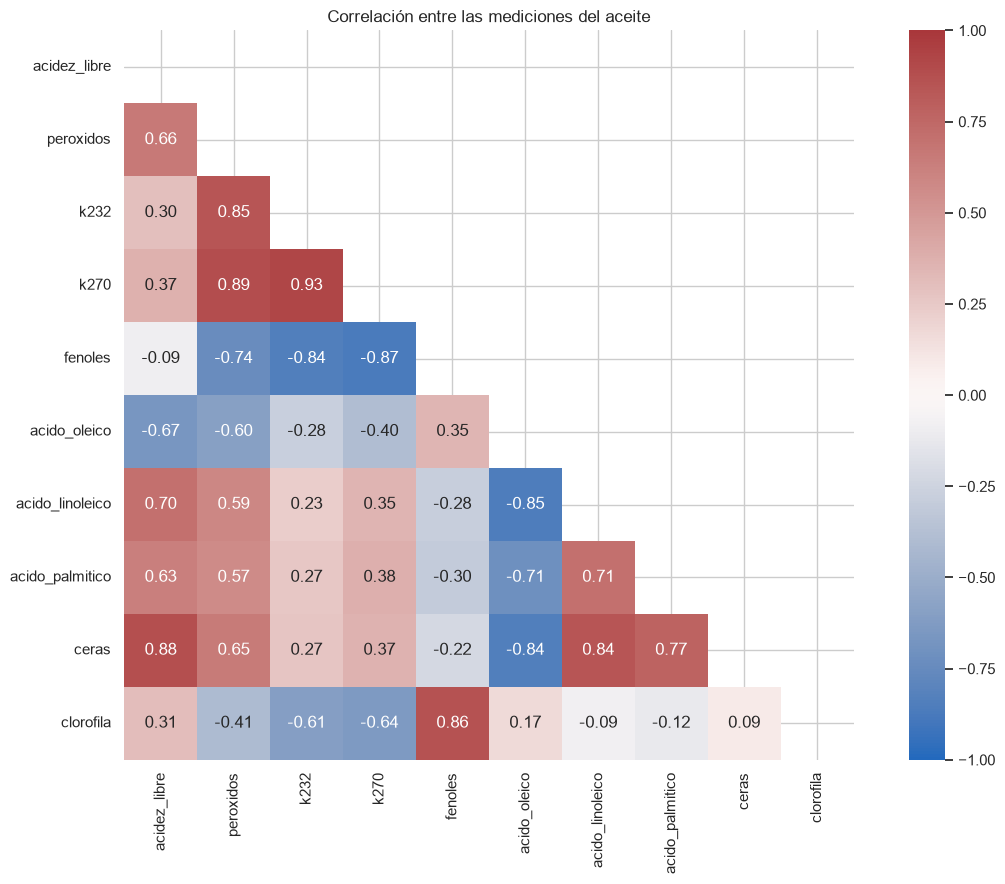

In [6]:
cormat = X.corr()
mask = np.triu(np.ones_like(cormat, dtype = bool))
plt.figure(figsize = (12, 9))
sns.heatmap(cormat, mask = mask, annot = True, fmt = ".2f",
            cmap = "vlag", vmin = -1, vmax = 1, square = True)
plt.title("Correlación entre las mediciones del aceite")
plt.tight_layout()
plt.show()

## 3. PCA con scikit-learn

Uso `StandardScaler` como en el ejemplo de clase y después ajusto el PCA. Retengo inicialmente las 10 componentes para comparar sus resultados. `svd_solver = "full"` calcula la solución sin un método aleatorio.

`StandardScaler` usa la desviación estándar con divisor n. Por eso, la varianza **muestral** de cada columna estandarizada es n/(n − 1) = 111/110 ≈ 1.0091. La covarianza de estos datos es la matriz de correlación multiplicada por ese factor común. Esto no cambia las cargas ni los porcentajes de varianza explicada.

In [7]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

pca = PCA(n_components = None, svd_solver = "full")
pca_fit = pca.fit(X_std)
scores = pca_fit.transform(X_std)

componentes = [f"PC{i + 1}" for i in range(X.shape[1])]
loadings = pd.DataFrame(pca_fit.components_.T, index = X.columns,
                        columns = componentes)
varianza = pca_fit.explained_variance_
proporcion = pca_fit.explained_variance_ratio_
acumulada = proporcion.cumsum()

tabla_pca = loadings.copy()
tabla_pca.loc["Varianza explicada"] = varianza
tabla_pca.loc["Proporción de varianza explicada"] = proporcion
tabla_pca.loc["Proporción de varianza acumulada"] = acumulada
display(tabla_pca.round(6))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
acidez_libre,0.297447,0.342720,0.431008,-0.047145,-0.032263,0.093017,-0.304105,-0.212485,-0.375441,-0.563737
peroxidos,0.392633,-0.099423,0.285143,-0.012204,0.094248,-0.010334,0.044768,-0.389748,0.768554,-0.030440
k232,0.306787,-0.341664,0.353967,0.011183,-0.064811,-0.221793,0.705702,0.157567,-0.290517,-0.055634
k270,0.342324,-0.300041,0.225565,0.027440,0.008573,-0.296597,-0.591987,0.481937,-0.012609,0.265035
fenoles,-0.298951,0.396964,0.140041,0.045058,-0.012730,-0.456699,0.121620,0.477966,0.368550,-0.378944
acido_oleico,-0.333875,-0.230837,0.356484,0.347397,0.675091,0.330492,-0.021092,0.120094,-0.005704,-0.087195
acido_linoleico,0.324189,0.272729,-0.296159,-0.369275,0.719316,-0.226880,0.096477,0.020569,-0.109763,0.076011
acido_palmitico,0.311332,0.222749,-0.272532,0.858285,0.033998,-0.166522,0.041329,-0.079707,-0.063149,0.039927
ceras,0.335115,0.331544,0.009844,-0.027197,-0.105327,0.663472,0.164280,0.511800,0.144406,0.125979
clorofila,-0.175751,0.470227,0.497977,0.016696,-0.015068,-0.129925,0.061747,-0.185110,-0.105165,0.658401


Las cargas son los coeficientes que combinan las variables estandarizadas para formar cada componente. En la tabla, las proporciones están entre 0 y 1. Por ejemplo, **PC1 explica 56.89 %** y **PC2 explica 27.61 %**. Juntas explican **84.49 %**.

PC1 contrasta las mediciones de oxidación y varias mediciones de composición con fenoles, ácido oleico y clorofila. PC2 separa principalmente clorofila y fenoles de K232 y K270. Las componentes no representan una clasificación automática de aceite puro o adulterado.

## 4. Número de componentes principales

### Proporción de varianza acumulada

Fijo como criterio conservar **al menos 90 %** de la variación. También comparo qué ocurre con metas de 80 % y 95 %.

In [8]:
resumen = pd.DataFrame({"Varianza": varianza,
                        "Varianza explicada (%)": proporcion * 100,
                        "Varianza acumulada (%)": acumulada * 100}, index = componentes)
display(resumen.round(4))

for meta in [0.80, 0.90, 0.95]:
    numero = np.searchsorted(acumulada, meta) + 1
    print(f"Para conservar al menos {meta:.0%}: {numero} componentes")

,Varianza,Varianza explicada (%),Varianza acumulada (%)
PC1,5.7404,56.8866,56.8866
PC2,2.7857,27.6058,84.4924
PC3,0.8005,7.9332,92.4256
PC4,0.3416,3.3852,95.8109
PC5,0.1463,1.4494,97.2603
PC6,0.0936,0.9271,98.1874
PC7,0.0674,0.6676,98.8549
PC8,0.0457,0.4531,99.3080
PC9,0.0390,0.3868,99.6948
PC10,0.0308,0.3052,100.0000


Para conservar al menos 80%: 2 componentes
Para conservar al menos 90%: 3 componentes
Para conservar al menos 95%: 4 componentes


Con dos componentes se supera el 80 %, pero no el 90 %. Con **tres componentes se conserva 92.43 %**, por lo que este criterio recomienda tres. Para llegar a 95 % se necesitan cuatro.

### Promedio de varianza explicada

Conservo las componentes cuya varianza explicada es mayor que el promedio de las 10 varianzas. Es el criterio de Kaiser adaptado al factor de `StandardScaler`.

In [9]:
promedio = varianza.mean()
numero_promedio = (varianza > promedio).sum()
print("Promedio de varianza:", round(promedio, 6))
print("Componentes por encima del promedio:", numero_promedio)
display(pd.DataFrame({"Varianza": varianza, "Mayor que el promedio": varianza > promedio},
                     index = componentes).round(6))

Promedio de varianza: 1.009091
Componentes por encima del promedio: 2


,Varianza,Mayor que el promedio
PC1,5.740377,True
PC2,2.785676,True
PC3,0.800534,False
PC4,0.341602,False
PC5,0.146259,False
PC6,0.093553,False
PC7,0.067363,False
PC8,0.045718,False
PC9,0.039035,False
PC10,0.030793,False


El promedio es **1.0091**. Solo PC1 y PC2 lo superan, por lo que este criterio recomienda **dos componentes**. PC3 explica menos variación que una variable estandarizada promedio.

### Scree plot

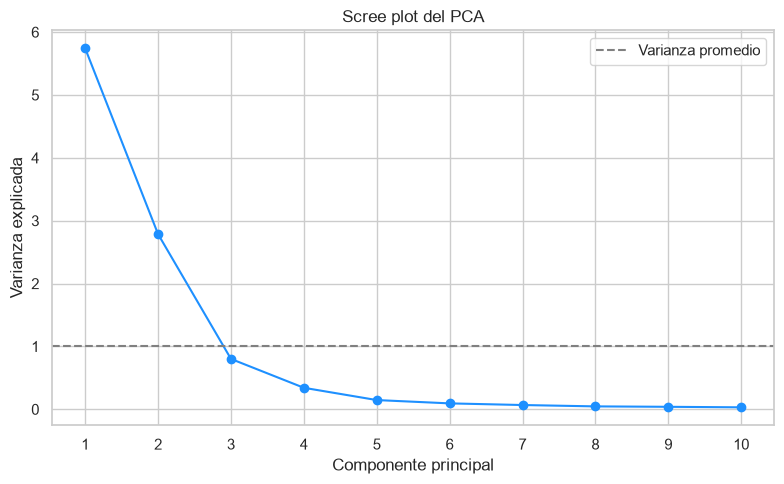

In [10]:
plt.figure(figsize = (8, 5))
plt.plot(range(1, 11), varianza, "o-", color = "dodgerblue")
plt.axhline(promedio, color = "gray", linestyle = "--", label = "Varianza promedio")
plt.xticks(range(1, 11))
plt.xlabel("Componente principal")
plt.ylabel("Varianza explicada")
plt.title("Scree plot del PCA")
plt.legend()
plt.tight_layout()
plt.show()

El descenso más fuerte ocurre entre las primeras componentes y la curva se vuelve mucho más plana a partir de PC3. El cambio de pendiente sugiere retener **dos o tres componentes**; el codo no es un criterio totalmente exacto.

**Decisión final: retengo tres componentes.** Mi prioridad es conservar al menos 90 % de la información. PC3 agrega **7.93 puntos porcentuales** y permite pasar de 84.49 % a 92.43 %. Aunque el criterio del promedio recomienda dos, la tercera mejora el resumen con solo una dimensión adicional. El biplot utiliza PC1 y PC2 porque es una gráfica de dos dimensiones; allí no se muestra el 15.51 % restante.

In [11]:
q = 3
scores_reducidos = pd.DataFrame(scores[:, :q], index = X.index,
                                columns = componentes[:q])
display(scores_reducidos.head())

,PC1,PC2,PC3
muestra,,,
M002,0.848069,2.229063,1.715979
M003,1.208817,-3.359303,-0.444232
M004,-1.664975,1.519657,0.138621
M005,-0.424395,-0.833435,1.135451
M006,3.126869,0.174224,0.114094


## 5. Proyección de la nueva muestra

Ingreso los valores en el mismo orden que las columnas de X. Utilizo **el mismo estandarizador y el mismo PCA ya ajustados**. No vuelvo a entrenarlos con la nueva observación.

In [12]:
nueva = pd.DataFrame({"acidez_libre": [0.82], "peroxidos": [13.4],
                      "k232": [2.31], "k270": [0.24], "fenoles": [278],
                      "acido_oleico": [70.4], "acido_linoleico": [10.7],
                      "acido_palmitico": [12.9], "ceras": [153], "clorofila": [5.2]})
nueva = nueva[X.columns]
nueva_std = scaler.transform(nueva)
nueva_scores = pca_fit.transform(nueva_std)
proyeccion = pd.DataFrame(nueva_scores[:, :q], index = ["Nueva muestra"],
                         columns = componentes[:q])
display(proyeccion.round(6))

,PC1,PC2,PC3
Nueva muestra,2.064506,-0.40567,-1.358915


La muestra nueva queda en **(PC1, PC2, PC3) = (2.064506, −0.405670, −1.358915)**. En el plano PC1–PC2 está a la derecha del centro, cerca de otras muestras. Su PC1 positivo se relaciona con un perfil relativamente mayor de algunas mediciones de oxidación y composición frente a fenoles y ácido oleico. Esta ubicación por sí sola no demuestra adulteración.

## 6. Biplot e interpretación

Los puntos representan las muestras y las flechas representan las variables. Para mostrar ambas en una misma gráfica divido los scores entre la desviación estándar de cada componente y multiplico las cargas por esa desviación. Es una forma de construir el biplot con las cantidades calculadas en clase.

Las flechas conservan una escala común y los ejes usan la misma proporción visual. Los ángulos aproximan las correlaciones y las longitudes muestran cuánta variación de cada variable queda representada en este plano. La nueva muestra se marca con una estrella.

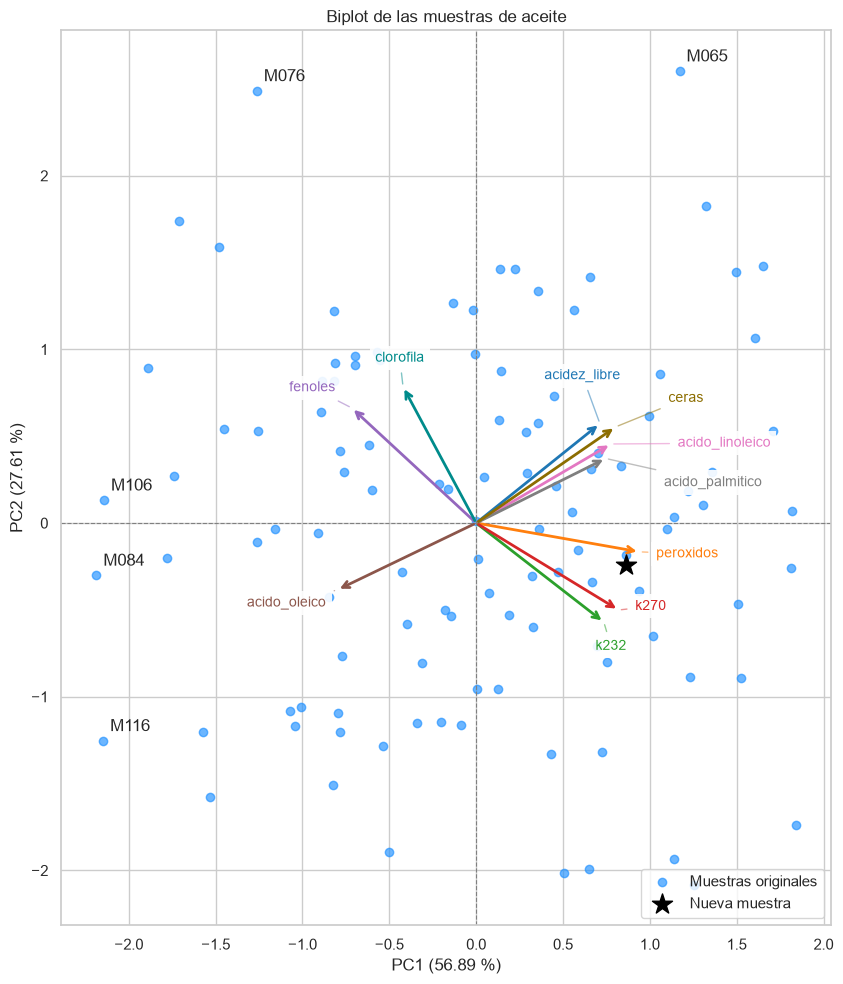

In [13]:
desv_pc = np.sqrt(varianza[:2])
puntos = scores[:, :2] / desv_pc
vectores = pca_fit.components_[:2].T * desv_pc
nueva_punto = nueva_scores[0, :2] / desv_pc

fig, ax = plt.subplots(figsize = (12, 10))
ax.scatter(puntos[:, 0], puntos[:, 1], color = "dodgerblue", alpha = 0.65,
           label = "Muestras originales")
ax.scatter(nueva_punto[0], nueva_punto[1], marker = "*", s = 230,
           color = "black", label = "Nueva muestra", zorder = 5)

colores = sns.color_palette("tab10", len(X.columns))
colores[8] = "#8c6d00"
colores[9] = "#008b8b"
ajustes = {"acidez_libre": (-40, 32), "ceras": (38, 18),
           "acido_linoleico": (48, -2), "acido_palmitico": (42, -20),
           "fenoles": (-45, 12), "clorofila": (-20, 18),
           "acido_oleico": (-65, -12), "peroxidos": (12, -4),
           "k232": (-6, -20), "k270": (12, 0)}
for i, variable in enumerate(X.columns):
    x, y = vectores[i]
    ax.annotate("", xy = (x, y), xytext = (0, 0),
                arrowprops = dict(arrowstyle = "->", color = colores[i], lw = 2))
    ax.annotate(variable, (x, y), xytext = ajustes[variable],
                textcoords = "offset points", color = colores[i], fontsize = 10,
                bbox = dict(facecolor = "white", alpha = 0.9, edgecolor = "none"),
                arrowprops = dict(arrowstyle = "-", color = colores[i], alpha = 0.5))

for muestra in ["M065", "M076", "M084", "M106", "M116"]:
    i = X.index.get_loc(muestra)
    ax.annotate(muestra, puntos[i], xytext = (5, 7), textcoords = "offset points")

ax.axhline(0, color = "gray", linestyle = "--", linewidth = 0.8)
ax.axvline(0, color = "gray", linestyle = "--", linewidth = 0.8)
ax.set_xlabel(f"PC1 ({proporcion[0] * 100:.2f} %)")
ax.set_ylabel(f"PC2 ({proporcion[1] * 100:.2f} %)")
ax.set_title("Biplot de las muestras de aceite")
ax.set_aspect("equal", adjustable = "box")
ax.legend(loc = "lower right")
plt.tight_layout()
plt.show()

### ¿Se observan clústers?

No se observan grupos claramente separados. Hay zonas con más puntos, pero la distribución es bastante continua. Por eso, con este biplot no puedo afirmar que existan clústers de aceites puros y adulterados. El archivo tampoco contiene etiquetas que identifiquen esas clases.

### ¿Existen observaciones alejadas del resto?

**M065** destaca en la parte superior derecha y **M076** en la parte superior izquierda. **M084, M106 y M116** se encuentran en el extremo izquierdo de PC1. Son muestras que conviene revisar por sus perfiles extremos. Las considero posibles observaciones atípicas visuales, aunque su posición no prueba un error ni adulteración. No las elimino, porque tienen mediciones completas.

### ¿Cuáles variables tienen mayor y menor varianza?

En las unidades originales, **fenoles** tiene la mayor varianza muestral (**6919.3440**) y **K270** la menor (**0.005620**). Esta comparación depende de las unidades.

En los datos estandarizados todas las variables tienen la misma varianza. Por eso, una flecha más larga no significa mayor varianza original: significa que esa variable está mejor representada por PC1 y PC2. En este plano, fenoles es la variable mejor representada (**94.34 %**) y ácido palmítico la menos representada (**68.84 %**). La siguiente tabla permite comparar todas las variables.

In [14]:
representacion = pd.DataFrame({"Longitud de la flecha": np.sqrt((vectores ** 2).sum(axis = 1)),
                               "Variación representada en PC1-PC2 (%)":
                               (vectores ** 2).sum(axis = 1) / (len(X) / (len(X) - 1)) * 100},
                              index = X.columns)
display(representacion.sort_values("Longitud de la flecha", ascending = False).round(4))

,Longitud de la flecha,Variación representada en PC1-PC2 (%)
fenoles,0.9757,94.3420
ceras,0.9751,94.2294
k270,0.9610,91.5148
peroxidos,0.9552,90.4257
k232,0.9303,85.7662
acidez_libre,0.9138,82.7551
acido_linoleico,0.9003,80.3205
clorofila,0.8907,78.6116
acido_oleico,0.8879,78.1230
acido_palmitico,0.8334,68.8359


### Correlación entre variables

Las flechas de **K232 y K270** apuntan en direcciones parecidas. Su correlación es **0.925**. También son altas las correlaciones de **peróxidos y K270 (0.887)**, **acidez y ceras (0.878)** y **fenoles y clorofila (0.863)**.

Las flechas opuestas sugieren relaciones negativas. Destacan **fenoles y K270 (−0.871)**, **ácido oleico y ácido linoleico (−0.853)** y **ácido oleico y ceras (−0.836)**.

Algunas relaciones son débiles, como **acidez y fenoles (−0.093)**, **clorofila y ácido linoleico (−0.086)** y **clorofila y ceras (0.090)**. Sus flechas son aproximadamente perpendiculares. Una correlación cercana a cero indica poca relación lineal, pero no demuestra independencia. Verifico los valores con la matriz de correlación, porque el biplot solo representa parte de la información.

### Contribución de las variables a PC1 y PC2

Calculo el porcentaje de contribución como la carga al cuadrado multiplicada por 100. Para cada componente, estos porcentajes suman 100 %.

In [15]:
contribuciones = loadings[["PC1", "PC2"]] ** 2 * 100
display(contribuciones.round(2))
print("Suma de contribuciones por componente:")
print(contribuciones.sum().round(2))

,PC1,PC2
acidez_libre,8.85,11.75
peroxidos,15.42,0.99
k232,9.41,11.67
k270,11.72,9.00
fenoles,8.94,15.76
acido_oleico,11.15,5.33
acido_linoleico,10.51,7.44
acido_palmitico,9.69,4.96
ceras,11.23,10.99
clorofila,3.09,22.11


Suma de contribuciones por componente:
PC1    100.0
PC2    100.0
dtype: float64


A **PC1** contribuyen más **peróxidos (15.42 %)**, **K270 (11.72 %)**, **ceras (11.23 %)** y **ácido oleico (11.15 %)**. El ácido oleico tiene carga negativa, mientras que las otras tres tienen carga positiva. **Clorofila (3.09 %)** aporta menos a esta componente.

A **PC2** contribuyen más **clorofila (22.11 %)**, **fenoles (15.76 %)**, **acidez (11.75 %)** y **K232 (11.67 %)**. K232 tiene carga negativa y las otras tres positiva. Peróxidos aporta solo **0.99 %** a PC2.

## 7. Información espectroscópica: rango y PCA por SVD

Cargo las mediciones espectroscópicas y separo el identificador. Cada fila representa una muestra y cada columna numérica representa una longitud de onda. Estos identificadores empiezan con E, por lo que analizo este archivo por separado, sin suponer una correspondencia con las muestras M del primer archivo.

In [16]:
spectra = pd.read_csv(ruta / "spectra.csv")
S = spectra.set_index("Muestra").apply(pd.to_numeric, errors = "coerce")
print("Dimensiones:", S.shape)
print("Datos faltantes:", S.isna().sum().sum())
display(S.head())

Dimensiones: (18, 40)
Datos faltantes: 0


,lambda_400nm,lambda_405nm,lambda_410nm,lambda_415nm,lambda_420nm,lambda_425nm,lambda_430nm,lambda_435nm,lambda_440nm,lambda_445nm,lambda_450nm,lambda_455nm,lambda_460nm,lambda_465nm,lambda_470nm,lambda_475nm,lambda_480nm,lambda_485nm,lambda_490nm,lambda_495nm,lambda_500nm,lambda_505nm,lambda_510nm,lambda_515nm,lambda_520nm,lambda_525nm,lambda_530nm,lambda_535nm,lambda_540nm,lambda_545nm,lambda_550nm,lambda_555nm,lambda_560nm,lambda_565nm,lambda_570nm,lambda_575nm,lambda_580nm,lambda_585nm,lambda_590nm,lambda_595nm
Muestra,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
E01,2.158571,2.017470,1.887481,1.949695,1.945481,1.860352,1.869416,1.695966,1.860076,1.729795,1.575411,1.776840,1.953292,2.094538,2.394347,2.423421,2.646348,3.121309,3.283312,3.521501,3.794503,3.735121,3.700825,3.619814,3.596407,3.296738,2.995418,2.636646,2.639708,2.309703,2.308370,2.117971,2.108868,1.985221,2.048255,1.837123,1.939800,2.044820,2.123052,2.039577
E02,1.961602,1.989152,2.091757,2.059962,2.358775,2.598891,2.587115,2.654203,2.955695,3.123497,3.122619,3.202328,3.039047,2.703225,2.683067,2.568641,2.186648,2.243932,2.250185,2.355888,2.118400,2.225050,2.192298,2.166760,2.205997,2.268144,2.249698,2.310097,2.175702,2.250803,2.300583,2.380615,2.170641,2.209446,2.080035,2.142589,1.942363,1.941735,2.021530,1.918047
E03,2.016751,1.911069,1.769032,1.861001,1.949103,1.813173,1.729236,1.357711,1.456232,1.503311,1.450223,1.623929,1.753754,1.883073,2.267157,2.604209,2.856490,3.163151,3.312292,3.679762,3.878443,3.873744,3.918237,3.776790,3.715714,3.243976,2.996246,2.599574,2.271570,1.886273,1.554012,1.484086,1.570965,1.496990,1.649520,1.561778,1.950525,1.987201,1.935734,2.032015
E04,2.128904,1.971000,1.861831,1.972696,1.818560,1.784866,1.602472,1.383667,1.364993,1.384228,1.250795,1.540338,1.373742,1.639591,1.931057,2.130079,2.379266,2.514732,2.798222,2.765877,2.951103,2.901297,3.050750,2.898485,2.815238,2.751186,2.599769,2.590562,2.472378,2.580021,2.604485,2.646418,2.508231,2.350486,2.342548,2.189763,2.073566,2.221495,2.021828,2.251073
E05,1.964938,1.901152,1.952119,1.880827,1.969461,1.815167,1.794423,1.790467,1.662897,1.658859,1.607509,1.788802,1.953925,1.947802,2.063710,2.352295,2.696279,2.758406,3.098529,3.089652,3.277249,3.443802,3.383433,3.260557,3.321650,3.038129,2.913289,2.771369,2.648665,2.688228,2.745694,2.592190,2.635534,2.373403,2.351189,2.282341,2.183977,2.066007,1.886666,2.008083


Hay **18 muestras y 40 mediciones** y no hay valores faltantes. Para esta parte uso la covarianza: todas las columnas son mediciones espectrales del mismo tipo y en la misma escala. No estandarizo cada longitud de onda, para conservar las diferencias en la variación de las señales. Sí centro las columnas, porque PCA estudia cambios respecto de la media.

In [17]:
rango_original = np.linalg.matrix_rank(S.to_numpy())
S_centrada = S - S.mean()
rango_centrado = np.linalg.matrix_rank(S_centrada.to_numpy())

print("Rango de la matriz original:", rango_original)
print("Rango de la matriz centrada:", rango_centrado)

Rango de la matriz original: 18
Rango de la matriz centrada: 17


El rango de la matriz original es **18** y el de la matriz centrada es **17**. Al centrar, la suma de las filas es cero para cada columna, así que ya no pueden existir 18 filas linealmente independientes. Como hay más variables que muestras, no es necesario construir una matriz de covarianza de 40 × 40 para encontrar las componentes.

### Solución con SVD

La SVD escribe la matriz centrada como **U · D · Vᵀ**. Las columnas de V son las cargas, los scores son **U · D** y la varianza de cada componente se obtiene como **s²/(n − 1)**, donde s es su valor singular.

In [18]:
U, valores_singulares, Vt = np.linalg.svd(S_centrada.to_numpy(), full_matrices = False)

scores_svd = U * valores_singulares
loadings_svd = Vt.T
varianza_svd = valores_singulares ** 2 / (len(S) - 1)
proporcion_svd = varianza_svd / varianza_svd.sum()
acumulada_svd = proporcion_svd.cumsum()
componentes_svd = [f"PC{i + 1}" for i in range(len(valores_singulares))]

print("Componentes devueltas por la SVD reducida:", len(valores_singulares))
print("Componentes con varianza distinta de cero:", rango_centrado)

Componentes devueltas por la SVD reducida: 18
Componentes con varianza distinta de cero: 17


### Tabla de resultados espectroscópicos

Incluyo las cargas de las 40 longitudes de onda y las tres filas de varianza solicitadas. La última columna corresponde a una componente de varianza prácticamente nula.

In [19]:
tabla_svd = pd.DataFrame(loadings_svd, index = S.columns, columns = componentes_svd)
tabla_svd.loc["Varianza explicada"] = varianza_svd
tabla_svd.loc["Proporción de varianza explicada"] = proporcion_svd
tabla_svd.loc["Proporción de varianza acumulada"] = acumulada_svd
display(tabla_svd.round(6))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18
lambda_400nm,-0.000028,0.001225,0.009193,0.058508,-0.059888,-0.277707,0.059065,-0.131836,0.341909,0.048543,-0.043118,-0.233493,-0.086193,-0.047078,-0.113002,-0.018772,0.113031,-0.404068
lambda_405nm,0.007839,0.004475,0.004233,-0.213109,0.091818,-0.088279,0.109523,0.148286,0.285890,0.052786,0.275530,-0.255074,-0.058372,-0.393855,0.366658,0.038960,0.130011,0.250355
lambda_410nm,0.022430,-0.024243,0.002559,-0.277433,-0.173203,0.135806,0.054781,-0.223798,-0.138738,-0.003989,-0.035898,-0.004950,-0.033478,0.146245,0.254391,0.024009,0.033208,-0.068829
lambda_415nm,0.035630,-0.040966,0.004538,0.121775,-0.322959,0.008816,0.007683,0.133680,0.154583,-0.272937,0.334458,0.024826,-0.102282,0.030235,0.019573,-0.036465,0.185782,-0.226548
lambda_420nm,0.049251,-0.099725,-0.014972,0.019905,0.136466,0.109863,-0.115655,0.076588,-0.107685,0.142192,-0.069282,-0.178687,-0.269946,0.054867,-0.056697,0.417039,0.103692,-0.058046
lambda_425nm,0.096881,-0.126765,-0.000335,-0.103885,0.101876,0.039288,-0.250143,0.104778,0.203066,0.138387,-0.205011,-0.021442,0.094902,-0.096836,0.143063,0.198068,-0.089446,0.160190
lambda_430nm,0.131215,-0.178112,-0.025709,0.146036,-0.099450,-0.083228,0.011348,-0.078390,0.110122,0.164285,-0.032805,-0.055622,0.122976,0.117771,-0.194284,-0.076048,-0.075808,0.042976
lambda_435nm,0.180111,-0.211695,-0.013268,-0.013653,-0.279621,-0.033301,0.309208,-0.109465,-0.205589,-0.034297,0.113846,0.066871,0.054340,-0.192255,-0.144799,0.059112,0.079064,0.267619
lambda_440nm,0.213384,-0.289434,-0.011146,0.201592,-0.176934,0.225758,-0.127398,-0.396875,0.108376,0.026388,0.012546,-0.024972,0.243332,-0.094670,0.173480,0.167702,0.200289,0.109514
lambda_445nm,0.231643,-0.336355,0.000491,-0.012343,0.081116,-0.113522,0.172019,0.022096,0.064167,-0.187719,-0.157802,-0.029730,0.106189,-0.011423,0.165476,-0.253672,-0.185562,0.084319


In [20]:
resumen_svd = pd.DataFrame({"Varianza": varianza_svd,
                            "Varianza explicada (%)": proporcion_svd * 100,
                            "Varianza acumulada (%)": acumulada_svd * 100},
                           index = componentes_svd)
display(resumen_svd.round(6))
print("Varianza de la última componente:", varianza_svd[-1])

,Varianza,Varianza explicada (%),Varianza acumulada (%)
PC1,12.569484,68.578280,68.578280
PC2,3.516640,19.186557,87.764837
PC3,2.048484,11.176394,98.941232
PC4,0.031689,0.172895,99.114127
PC5,0.025898,0.141300,99.255428
PC6,0.021829,0.119099,99.374527
PC7,0.020184,0.110125,99.484652
PC8,0.019533,0.106568,99.591220
PC9,0.014839,0.080962,99.672182
PC10,0.012778,0.069713,99.741895


Varianza de la última componente: 1.5626768402249938e-30


**¿El número de componentes coincide con el rango?** La SVD reducida devuelve **18 componentes**, pero la última tiene varianza aproximadamente **1.56 × 10⁻³⁰**, que es cero dentro de la precisión numérica. Sus cargas no describen una dirección con variación y no deben interpretarse como un patrón útil.

Existen **17 componentes con varianza positiva**, que coinciden con el rango de la **matriz centrada**. No coinciden con el rango 18 de la matriz original, porque PCA se realiza después de centrar. Las otras 22 direcciones hasta completar las 40 variables también tienen varianza nula y no aparecen en esta SVD reducida.

PC1 explica **68.58 %**, PC2 **19.19 %** y PC3 **11.18 %**. Las dos primeras conservan **87.76 %**, y las tres primeras **98.94 %**. Aunque hay 17 componentes no nulas, tres bastan para conservar casi toda la variación de estos espectros.

### Scores en dos dimensiones

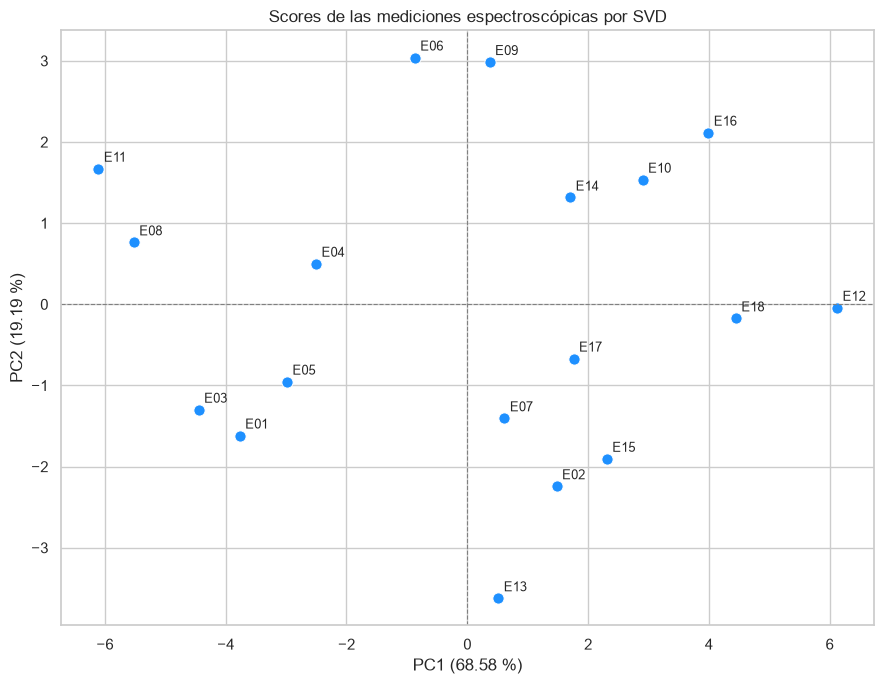

In [21]:
df_svd = pd.DataFrame(scores_svd[:, :2], index = S.index, columns = ["PC1", "PC2"])
fig, ax = plt.subplots(figsize = (9, 7))
sns.scatterplot(data = df_svd, x = "PC1", y = "PC2", color = "dodgerblue", s = 65, ax = ax)
for muestra, fila in df_svd.iterrows():
    ax.annotate(muestra, (fila["PC1"], fila["PC2"]),
                xytext = (4, 5), textcoords = "offset points", fontsize = 9)
ax.axhline(0, color = "gray", linestyle = "--", linewidth = 0.8)
ax.axvline(0, color = "gray", linestyle = "--", linewidth = 0.8)
ax.set_xlabel(f"PC1 ({proporcion_svd[0] * 100:.2f} %)")
ax.set_ylabel(f"PC2 ({proporcion_svd[1] * 100:.2f} %)")
ax.set_title("Scores de las mediciones espectroscópicas por SVD")
plt.tight_layout()
plt.show()

La gráfica conserva **87.76 %** de la variación espectroscópica. Los puntos cercanos representan muestras con señales parecidas en las dos principales direcciones de variación. Para estudiar diferencias adicionales sería conveniente incluir PC3, que agrega 11.18 puntos porcentuales.

## 8. Conclusión

El PCA de los datos fisicoquímicos permite resumir las 10 variables con **tres componentes** y conservar **92.43 %** de su variación. El biplot muestra relaciones claras entre las variables de oxidación, composición, fenoles y clorofila, aunque no separa grupos de forma evidente. La nueva muestra puede proyectarse con el mismo modelo y queda dentro de la región general de los datos en PC1–PC2.

En los espectros, la SVD permite trabajar con 40 variables y solo 18 muestras. Después de centrar, hay **17 componentes con varianza positiva**, pero las primeras tres explican **98.94 %** de la variación. Estos resultados ayudan a identificar patrones y muestras que conviene revisar. Para confirmar adulteración se necesitarían muestras de referencia y pruebas específicas que distingan aceite de oliva de aceite de girasol.

**Entrega:** el archivo HTML contiene el procedimiento, el código, las tablas y las gráficas. Se acompaña del notebook `.ipynb`, que permite repetir el análisis. Ambos archivos se entregan en Canvas.